In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

from pprint import pprint
import pickle

from functools import partial

import numpy as np
from sklearn.preprocessing import scale
from sklearn.decomposition import PCA
# import sklearn.metrics as metrics
from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt
import matplotlib.animation as ani

import mlgrad.models as models
import mlgrad.regr as regr
import mlgrad.cls as cls
import mlgrad.pca as pca
import mlgrad.plots as plots
import mlgrad.funcs as funcs
import mlgrad.funcs2 as funcs2
import mlgrad.loss as loss
import mlgrad.gd as gd
import mlgrad.smooth as smooth
import mlgrad.inventory as inventory
from mlgrad.af import averaging_function

import rampy
import pybaselines
import random

from irsa import io
from irsa.preprocess import despike, utils
import irsa.widgets as widgets
import irsa.spectra as spectra
import irsa.io as io

import scipy.special as special

import copy

import ipywidgets
from IPython.display import display

import sys
print(sys.version)

# %matplotlib widget

3.14.7 (main, Sep 13 2026, 08:30:29) [GCC 16.2.0]


In [2]:
def plot_params(lfm, p_threshold=1.0e-4):
    ax = plt.twinx(plt.gca())
    n = lfm.n_input
    mask = np.zeros(n, np.uint8)
    for mod in lfm.models:
        param1 = np.asarray(mod.param[1:])
        # print(param1[0])
        param_p = param1.copy()
        param_m = param1.copy()
        param_p[param1 < 0] = 0
        param_m[param1 > 0] = 0
        mask = mask | (abs(param1) > p_threshold)
        ax.vlines(range(mod.n_input), param_m, param_p, color='k')
    ax.minorticks_on()
    s = mask.astype("i").sum()
    plt.title(f'Значения коэффициентов классификатора:  #(abs(param) > {p_threshold}) = {s}')

def plot_param(param, p_threshold=1.0e-4):
    ax = plt.twinx(plt.gca())
    n = len(param)
    param_p = param.copy()
    param_m = param.copy()
    param_p[param < 0] = 0
    param_m[param > 0] = 0
    ax.vlines(range(n), param_m, param_p, color='k')
    ax.minorticks_on()
    if p_threshold != 0:
        mask = (abs(param) > p_threshold)
        s = mask.astype("i").sum()
        plt.title(f'#(abs(param) > {p_threshold}) = {s}')

In [3]:
def rescale_by(X, Y):
    mu_y = np.median(Y, axis=0)
    sigma_y = np.median(abs(Y - mu_y))
    mu_x = np.median(X, axis=0)
    sigma_x = np.median(abs(X - mu_x))
    return (X - mu_x) / sigma_x * sigma_y + mu_y
    

In [4]:
def plot_pca(xs, Ys, labels, colors=None, kind="l2/l2", q=1.0, m=5, n_iter=200, tol=1.0e-6, 
             verbose=False, plot_reconstructed=False, plot_eigenval=True, plot_eigenvec=False, ticks=False):

    Y = np.vstack(Ys)
    if kind == "l2/lq":
        c, As, Ls = pca.find_loc_and_pc_l2_lq(Y, m, q, eps=0, n_iter=n_iter, tol=tol, verbose=verbose)
    elif kind == "l2/l1":
        c, As, Ls = pca.find_loc_and_pc_l2_l1(Y, m, n_iter=n_iter, tol=tol, verbose=verbose)
    elif kind == "l1/l2":
        c, As, Ls = pca.find_loc_and_pc_l1_l2(Y, m, n_iter=n_iter, tol=tol, verbose=verbose)
    elif kind == "l1/l1":
        c, As, Ls = pca.find_loc_and_pc_l1_l1(Y, m, verbose=verbose)
    else:
        c, As, Ls = pca.find_loc_and_pc(Y, m, n_iter=n_iter, tol=tol, verbose=verbose)

    Us = [pca.transform(ys, c, As) for ys in Ys]

    plt.figure(figsize=(15,4))
    for i in range(4):
        plt.subplot(1,4,i+1)
        if colors is None:
            for U, label in zip(Us, labels):
                plt.scatter(U[:,i], U[:,i+1], s=36, edgecolors='k', linewidth=0.5, label=label)
        else:
            for U, label, color in zip(Us, labels, colors):
                plt.scatter(U[:,i], U[:,i+1], s=36, c=color, edgecolors='k', linewidth=0.5, label=label)
        plt.xlabel(str(i+1))
        plt.ylabel(str(i+2))
        if not ticks:
            plt.xticks([])
            plt.yticks([])
        plt.legend()
    plt.tight_layout()
    plt.legend()
    plt.show()

    if plot_reconstructed:
        plt.figure(figsize=(12,5))
        plt.title("Reconstruction from PCs")
        for U, label in zip(Us, labels):
            plt.plot(xs, (U @ As + c).mean(axis=0), label=label)
        plt.tight_layout()
        plt.minorticks_on()
        plt.legend()
        plt.show()

    Ls /= Ls.sum()

    if plot_eigenvec:
        plt.figure(figsize=(12,6))
        for i,a in enumerate(As[:10]):
            plt.plot(xs, a*Ls[i], label=str(i+1))
        plt.ylabel("PCs")
        plt.legend()
    
        plt.minorticks_on()
        plt.grid(lw=0.5, ls=':')
        plt.tight_layout()
        plt.show()
    
    if plot_eigenval:
        plt.figure(figsize=(10,3))
        plt.title("Собственные числа")
        plt.plot(Ls, marker='o', ms=2)
        plt.yscale('log')
        # plt.xscale('log')
        plt.grid(ls=':', lw=0.5)
        plt.ylabel(r"$\log\lambda$")
        plt.minorticks_on()
        plt.show()

    return c, As


In [5]:
def preprocess_step1(dd):
    print("Step 1")
    dd.crop(400)    
    dd.despike(3.5)
    dd.multiplicative_scatter_correction()
    dd.denoise_svd()
    dd.flatten()
    dd.multiplicative_scatter_correction()
    # dd.robust_averaging()
    # dd.multiplicative_scatter_correction()
    dd.scale_by_mean()
    dd.filter(kind="m-zscore", tau=2.0)

def preprocess_step2(dd):
    print("Step 2")
    dd.multiplicative_scatter_correction()
    dd.denoise_svd()
    dd.subtract_baselines(tau2=1.0, #tau1=-1.0e-4,    
                      func=funcs.RStep(0.0, 1.0e-5),
                      func2_e=inventory.relative_abs_max,
                      verbose=False, n_jobs=8, d=2)
    dd.multiplicative_scatter_correction()
    dd.scale_by_mean()
    dd.filter(kind="m-zscore", tau=2.0)


# Спектры из 23-й серии

In [6]:
path = f"/home/intellimath/YD/repos/spectra/23_SE"
dd23 = io.load_spectra(path, {
                            "вид_бактерий":["KL", "SA"], 
                            "номер_цикла":["23"], 
                            "лизис":["термический"],
                            "отсечки_по_молекулярной_массе": ["sediment"],
                           }, verbose=False)


In [7]:
preprocess_step1(dd23)

dd23_SA580 = dd23.union("SA580", **{"вид_бактерий":"SA", "штамм_бактерий":"580"})
dd23_SA0064 = dd23.union("SA0064", **{"вид_бактерий":"SA", "штамм_бактерий":"0064"})
dd23_KL238 = dd23.union("KL238", **{"вид_бактерий":"KL", "штамм_бактерий":"238"})
dd23_KL1568 = dd23.union("KL1568", **{"вид_бактерий":"KL", "штамм_бактерий":"1568"})

preprocess_step2(dd23_SA580)
preprocess_step2(dd23_SA0064)
preprocess_step2(dd23_KL238)
preprocess_step2(dd23_KL1568)

dd23_flat = {"SA580": dd23_SA580, "SA0064": dd23_SA0064, "KL238": dd23_KL238, "KL1568": dd23_KL1568}

Y23_SA580 = dd23_SA580.y
Y23_SA0064 = dd23_SA0064.y
Y23_KL238 = dd23_KL238.y
Y23_KL1568 = dd23_KL1568.y

names23 = ["SA580", "SA0064", "KL238", "KL1568"]
Ys23 = [Y23_SA580, Y23_SA0064, Y23_KL238, Y23_KL1568]
Y23 = np.concatenate(Ys23, axis=0)

xs = dd23.same_x()
print(len(xs), len(Y23_SA580), len(Y23_SA0064), len(Y23_KL238), len(Y23_KL1568))


Step 1
Step 2
SA580
Step 2
SA0064
Step 2
KL238
Step 2
KL1568
803 137 141 152 169


In [8]:
dd23.plot_spectra(lw=1.0)

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('KL_1568__23_5…

In [9]:
@ipywidgets.interact(key=names23)
def plot_spectra_cls(key):
    dd23_flat[key].plot_spectra(lw=1.0)

interactive(children=(Dropdown(description='key', options=('SA580', 'SA0064', 'KL238', 'KL1568'), value='SA580…

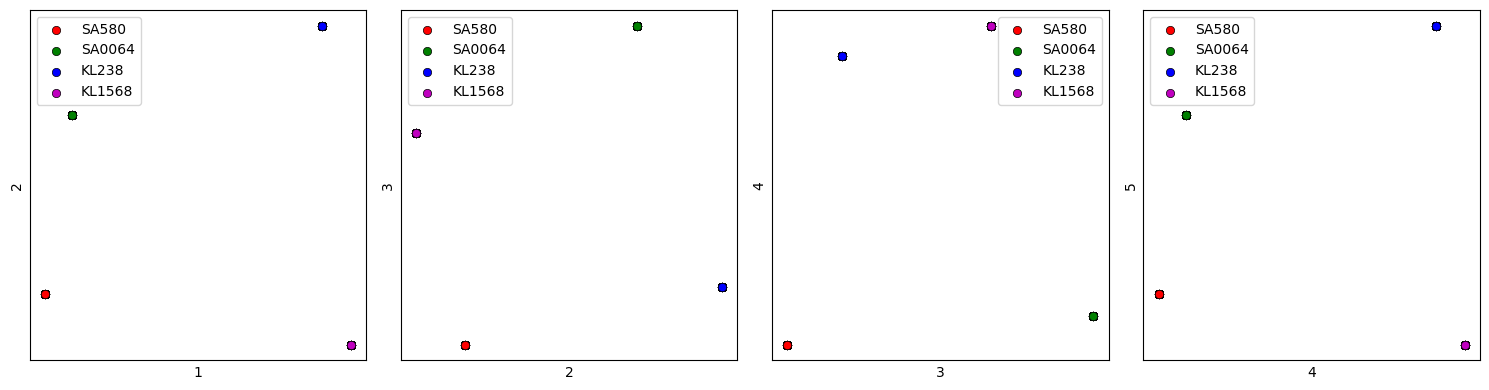

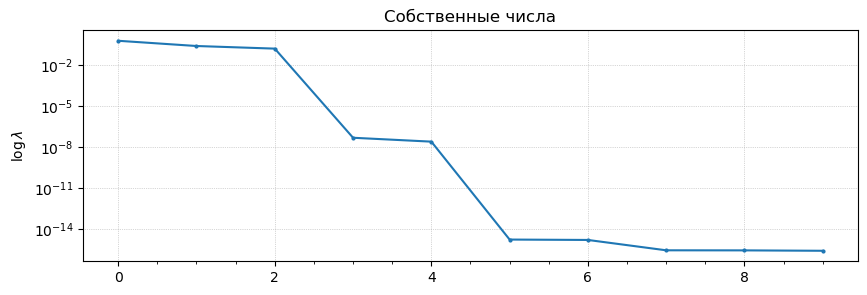

In [10]:
c23, As23 = plot_pca(xs, Ys23, names23, ["r", "g", "b", "m"], m=10)

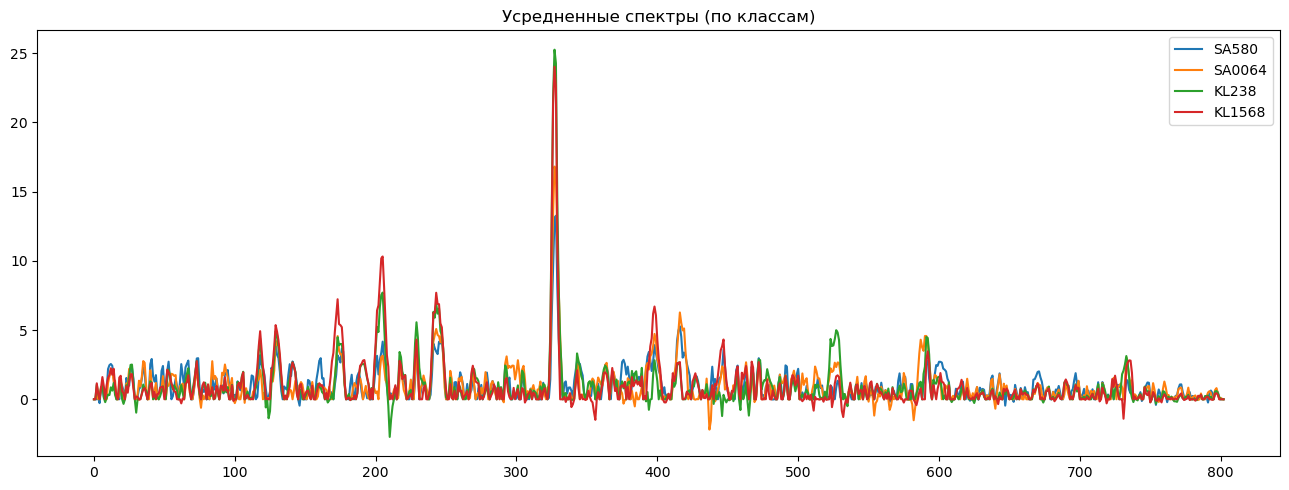

In [11]:
plt.figure(figsize=(13,5))
plt.title("Усредненные спектры (по классам)")
for name, Y in zip(names23, Ys23):
    # if "KL" in name:
        plt.plot(np.median(Y, axis=0), label=name)
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
path = f"/home/intellimath/YD/repos/spectra/20"
dd20 = io.load_spectra(path, {
                            "вид_бактерий":["SA", "SS", "SH"], 
                            "номер_цикла":["20"], 
                            "лизис":["термический"],
                            "номер_повтора":["1", "2", "3"],
                            "отсечки_по_молекулярной_массе": ["sediment"],
                           })


In [13]:
preprocess_step1(dd20)

dd20_SA = dd20.union("SA", **{"вид_бактерий":"SA"})
dd20_SS = dd20.union("SS", **{"вид_бактерий":"SS"})
dd20_SH = dd20.union("SH", **{"вид_бактерий":"SH"})

preprocess_step2(dd20_SA)
preprocess_step2(dd20_SS)
preprocess_step2(dd20_SH)

# dd20_SA.multiplicative_scatter_correction()
# dd20_SS.multiplicative_scatter_correction()
# dd20_SH.multiplicative_scatter_correction()

dd20_flat = {"SA97": dd20_SA, "SS17": dd20_SS, "SH15": dd20_SH,}

Y20_SA = dd20_SA.y
Y20_SS = dd20_SS.y
Y20_SH = dd20_SH.y

names20 = ["SA97", "SS17", "SH15"]
Ys20 = [Y20_SA, Y20_SS, Y20_SH]
Y20 = np.concatenate(Ys20, axis=0)

xs = dd20.same_x()
print(len(xs), len(Y20_SA), len(Y20_SS), len(Y20_SH))


Step 1
Step 2
SA
Step 2
SS
Step 2
SH
803 378 373 308


In [14]:
@ipywidgets.interact(key=names20)
def plot_spectra_cls(key):
    dd20_flat[key].plot_spectra(lw=1.0)

interactive(children=(Dropdown(description='key', options=('SA97', 'SS17', 'SH15'), value='SA97'), Output()), …

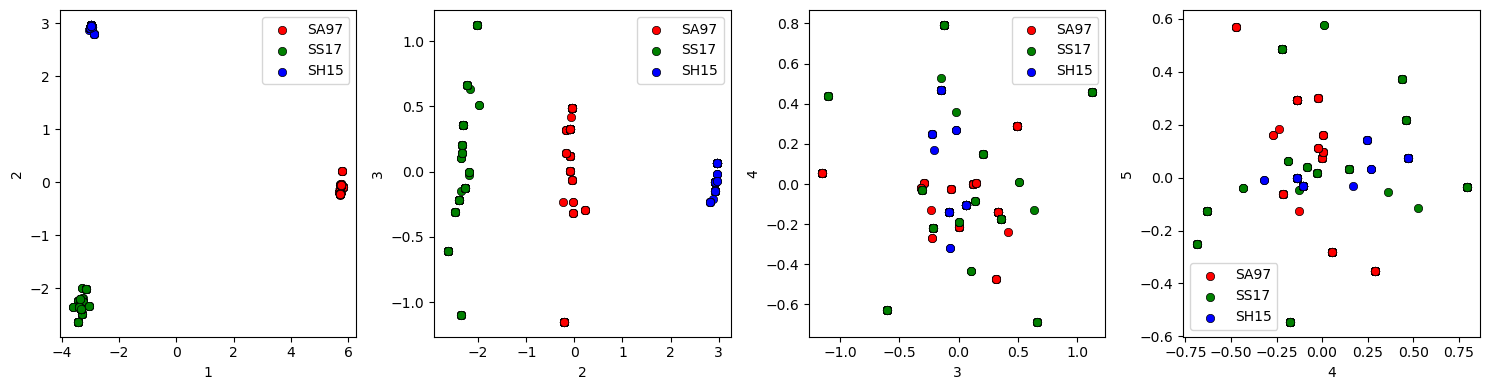

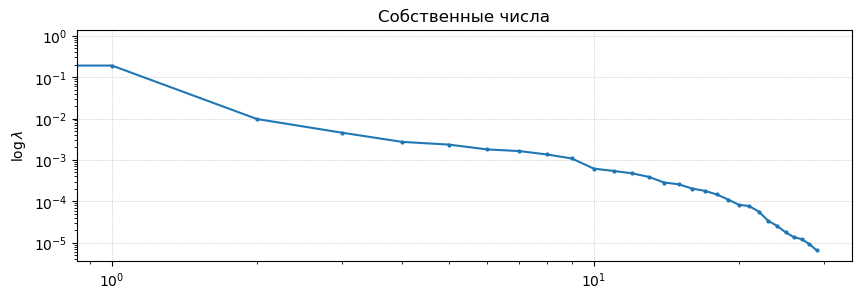

In [15]:
c20, As20 = plot_pca(xs, Ys20, names20, ["r", "g", "b", "m"], m=30)

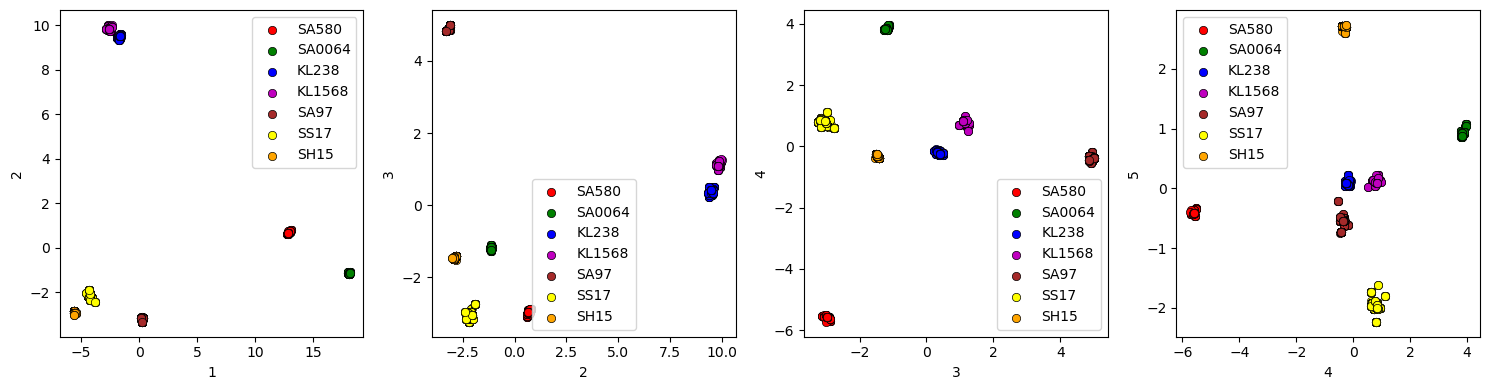

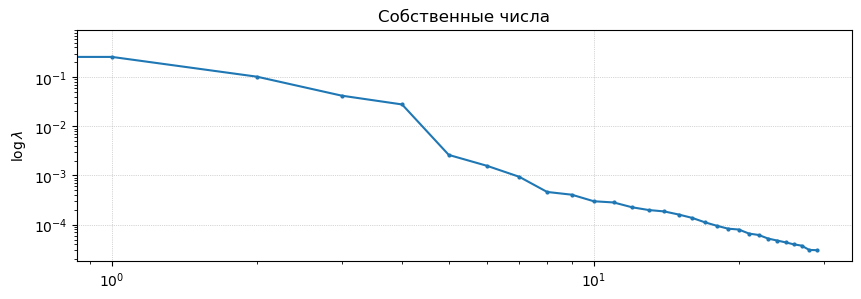

In [16]:
_ = plot_pca(xs, Ys23 + Ys20, names23 + names20, ["r", "g", "b", "m", "brown", "yellow", "orange"], m=30)